# Executive Summary

**Overview**
This report analyzes a dataset of 7,043 IT customers to identify the primary drivers of user churn and provide actionable strategies to improve retention. The dataset includes customer demographics, account information, and subscribed services. The baseline churn rate stands at 26.6%.

**Key Findings**
1. **Contract Volatility:** Customers on month-to-month contracts are highly volatile, churning at a rate of 42.7%, compared to just 2.8% for those on two-year agreements.
2. **The Critical First Window:** The highest risk of churn occurs within a customer's first five months of service. If a user is successfully retained past the first year, their likelihood of leaving drops significantly.
3. **Premium Service Dissatisfaction:** Customers paying for premium Fiber Optic internet churn at a much higher rate (41.9%) than those on basic DSL (19.0%), suggesting the premium experience does not currently justify the higher monthly cost.
4. **Impact of Technical Support:** Customers without dedicated technical support are nearly three times more likely to churn (41.6%) than those who have it (15.1%).

**Business Impact**
Addressing these pain points in the early stages of the customer lifecycle and within the premium Fiber Optic tiers is critical for stabilizing recurring revenue and improving overall customer lifetime value.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set the clean visual style for the final presentation
plt.style.use('seaborn-v0_8')

# 1. Load the data
df = pd.read_csv('IT_customer_churn.csv')
df.duplicated().sum()  # Check for duplicates

 # 2. Data Cleaning
# Convert 'TotalCharges' from text to numeric, forcing empty strings to NaN
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# Drop the 11 rows with missing TotalCharges (these are brand new customers with 0 tenure)
df.dropna(subset=['TotalCharges'], inplace=True)

# Create a binary Churn column (1 for Yes, 0 for No) to make plotting easier
df['Churn_Binary'] = df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

# Verify the cleaning
print("Remaining rows:", len(df))
print("Null values remaining:\n", df.isnull().sum()[df.isnull().sum() > 0])

Remaining rows: 7032
Null values remaining:
 Series([], dtype: int64)


# Methodology
To prepare the dataset for analysis, `TotalCharges` was converted to a numeric data type, and 11 rows containing null values (representing new customers with zero tenure) were dropped. A binary churn column was created to facilitate quantitative visualization. The analysis focuses exclusively on identifying correlations between account services, contract lengths, and the likelihood of churn.

# Key Findings
*The following visualizations highlight the primary drivers of customer churn.*

### 1. Churn by Contract Type

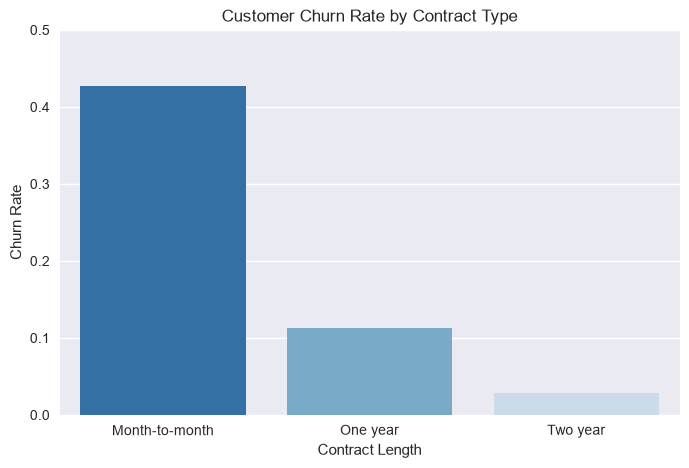

In [12]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Contract', y='Churn_Binary', hue='Contract', legend=False, errorbar=None, palette='Blues_r')
plt.title('Customer Churn Rate by Contract Type')
plt.ylabel('Churn Rate')
plt.xlabel('Contract Length')
plt.ylim(0, 0.5)
plt.show()



### 2. Churn by Tenure

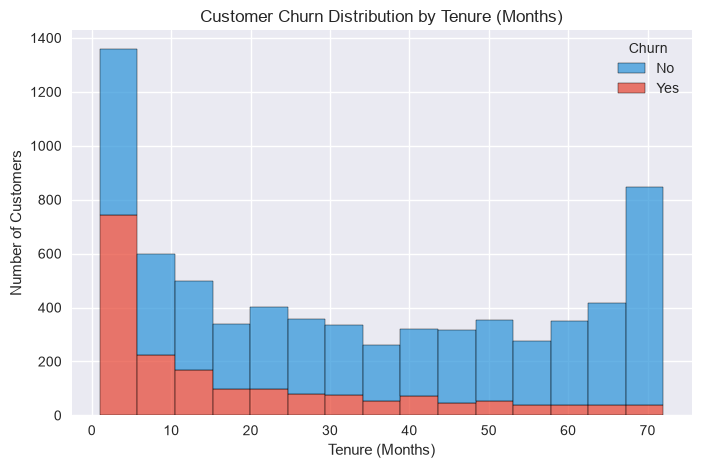

In [13]:

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='tenure', hue='Churn', multiple='stack', palette={'Yes': '#e74c3c', 'No': '#3498db'})
plt.title('Customer Churn Distribution by Tenure (Months)')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')
plt.show()



### 3. Monthly Charges vs. Churn by Internet Service

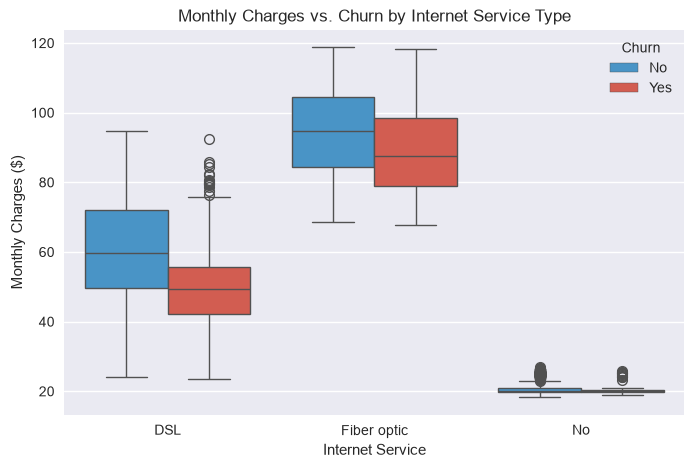

In [14]:

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='InternetService', y='MonthlyCharges', hue='Churn', palette={'Yes': '#e74c3c', 'No': '#3498db'})
plt.title('Monthly Charges vs. Churn by Internet Service Type')
plt.xlabel('Internet Service')
plt.ylabel('Monthly Charges ($)')
plt.show()



### 4. Finding Insight 4: The Impact of Tech Support

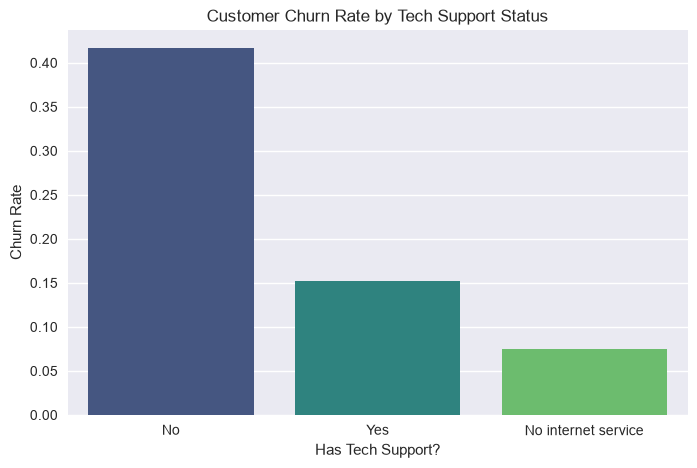

In [17]:
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='TechSupport', y='Churn_Binary', hue='TechSupport', legend=False, errorbar=None, palette='viridis')
plt.title('Customer Churn Rate by Tech Support Status')
plt.ylabel('Churn Rate')
plt.xlabel('Has Tech Support?')
plt.show()

### The exact percentages for Tech Support

In [18]:

print("\n--- Insight 4: Tech Support ---")
print(df.groupby('TechSupport')['Churn_Binary'].mean() * 100)


--- Insight 4: Tech Support ---
TechSupport
No                     41.647465
No internet service     7.434211
Yes                    15.196078
Name: Churn_Binary, dtype: float64
